<img src="https://iict-space.heig-vd.ch/apu/wp-content/uploads/sites/21/2022/01/2020-slim.png" alt="Logo HEIG-VD" style="width: 80px;" align="right"/>

# Cours APN - Labo 4 : Classification non supervisée

**Étudiants :** Ismael Giovannetti & Mouhamed Sakho

## Résumé
Le but de ce laboratoire est de réaliser des expériences de classification non-supervisée d'articles.  L'approche se base sur des vecteurs en basse dimension (*embeddings*) qui représentent les classes, qui seront comparés avec les vecteurs en basse dimension (*embeddings*) représentant les documents.  Ces *embeddings* seront obtenus soit grâce à un modèle de type Sentence BERT.  La méthode sera testée sur un corpus d'articles provenant de rubriques connues, ce qui permettra d'évaluer les méthodes.

In [1]:
# Librairies générales
import numpy as np
from tqdm import tqdm

In [2]:
# Similarité entre vecteurs (mots, catégories ou textes)
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
# Librairies pour l'évaluation
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

## 1. Préparation des données

Vous utiliserez un corpus d'environ 200'000 articles (titres et résumés) [diponibles sur Kaggle](https://www.kaggle.com/datasets/rmisra/news-category-dataset/versions/2) (V2, 80 Mo, nécessite un login) mais dont une copie est **fournie sur Cyberlearn**.

**a.** Veuillez charger le corpus à l'aide des instructions données ci-dessous, puis afficher les statistiques suivantes :
  * un exemple d'article
  * nombre d'articles pour chaque catégorie (ou classe) par ordre décroissant
  * nombre total d'articles
  * nombre d'articles sans `headline`
  * nombre d'articles sans `short_description`
  * nombre d'articles dont la longueur de `headline + short_description` est inférieure ou égale à 4 caractères
  * longueur moyenne de `headline + short_description`

In [4]:
import json
from collections import Counter # pour calculer facilement le nombre d'articles par categorie

In [5]:
import os
data_path = 'News_Category_Dataset_v2.json'
if os.path.isdir(data_path):  # l'archive Cyberlearn place le fichier dans un dossier du même nom
    data_path = os.path.join(data_path, 'News_Category_Dataset_v2.json')

corpus  = []
with open(data_path, mode='r', errors='ignore') as json_file:
    for dic in json_file:
        corpus.append(json.loads(dic))

In [6]:
print("Exemple d'article :")
print(json.dumps(corpus[0], indent=2, ensure_ascii=False))

print("\nNombre d'articles par catégorie (ordre décroissant) :")
category_counts = Counter(article['category'] for article in corpus)
for cat, n in category_counts.most_common():
    print(f"  {cat:<15s} {n:>6d}")

lengths = np.array([len(a['headline']) + len(a['short_description']) for a in corpus])
print(f"\nNombre total d'articles                           : {len(corpus)}")
print(f"Nombre de catégories                              : {len(category_counts)}")
print(f"Articles sans headline                            : {sum(1 for a in corpus if not a['headline'].strip())}")
print(f"Articles sans short_description                   : {sum(1 for a in corpus if not a['short_description'].strip())}")
print(f"Articles avec len(headline + short_description) <= 4 : {int((lengths <= 4).sum())}")
print(f"Longueur moyenne de headline + short_description  : {lengths.mean():.1f} caractères")

Exemple d'article :
{
  "category": "CRIME",
  "headline": "There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV",
  "authors": "Melissa Jeltsen",
  "link": "https://www.huffingtonpost.com/entry/texas-amanda-painter-mass-shooting_us_5b081ab4e4b0802d69caad89",
  "short_description": "She left her husband. He killed their children. Just another day in America.",
  "date": "2018-05-26"
}

Nombre d'articles par catégorie (ordre décroissant) :
  POLITICS         32739
  WELLNESS         17827
  ENTERTAINMENT    16058
  TRAVEL            9887
  STYLE & BEAUTY    9649
  PARENTING         8677
  HEALTHY LIVING    6694
  QUEER VOICES      6314
  FOOD & DRINK      6226
  BUSINESS          5937
  COMEDY            5175
  SPORTS            4884
  BLACK VOICES      4528
  HOME & LIVING     4195
  PARENTS           3955
  THE WORLDPOST     3664
  WEDDINGS          3651
  WOMEN             3490
  IMPACT            3459
  DIVORCE           3426
  CRIME             3405
  MEDIA             

**b.** Veuillez écrire une fonction qui sélectionne les articles d'une ou plusieurs catégories (données sous forme de liste, p.ex. `['MONEY', 'SCIENCE']`) et retourne leurs textes et leurs catégories.  Plus précisément :
* la fonction retourne une liste de textes et une liste de leurs catégories (même longueur)
* chaque article est composé du `headline` et de la `short_description`, séparés par un point et un espace
* la fonction retourne seulement les textes dont la longueur finale est supérieure ou égale à 5 caractères
* la fonction affiche pour chaque catégorie son nom et le nombre d'articles qu'elle contient.

In [7]:
def select_texts_categories(corpus, selected_categories):
    """Retourne les textes (headline. short_description) et les catégories des articles
    appartenant aux catégories sélectionnées, en ignorant les textes de moins de 5 caractères."""
    texts, categories = [], []
    for article in corpus:
        if article['category'] in selected_categories:
            text = article['headline'] + '. ' + article['short_description']
            if len(text) >= 5:
                texts.append(text)
                categories.append(article['category'])
    counts = Counter(categories)
    for cat in selected_categories:
        print(f"{cat:<10s} : {counts[cat]} articles")
    return texts, categories

**c.** Veuillez exécuter la fonction sur les catégories MONEY et SCIENCE, puis afficher un extrait du résultat (article et catégorie).

In [8]:
texts, categories = select_texts_categories(corpus, ['MONEY', 'SCIENCE'])
print(f"Total : {len(texts)} articles\n")
for i in [0, 1, len(texts) - 1]:
    print(f"[{categories[i]}] {texts[i]}\n")

MONEY      : 1707 articles
SCIENCE    : 2178 articles
Total : 3885 articles

[SCIENCE] Scientists Turn To DNA Technology To Search For Loch Ness Monster. The researchers plan to scour the Loch Ness next month for evidence of its supposed inhabitant.

[SCIENCE] Unusual Asteroid Could Be An Interstellar Guest To Our Solar System. The supposed "interstellar immigrant" is located near Jupiter but has an atypical orbit.

[SCIENCE] Aurora Borealis Caused By Huge Solar Storm Shimmers Over Norway (VIDEO). Aurora borealis can typically only be seen at high northern latitudes. But during periods of high solar activity - such as



___
## 2. Classification non supervisée avec des embeddings Sentence BERT

La méthode de classification comporte trois étapes :
* création des *embeddings* des catégories avec un modèle de type Sentence BERT (déjà utilisé dans un labo précédent)
* création des *embeddings* du texte à classifier avec le même modèle
* classification : choisir la catégorie dont l'*embedding* est le plus similaire à celui du texte donné.

**a.** Veuillez instancier un encodeur de type SentenceTransformer avec le modèle all-MiniLM-L6-v2, disponible via Hugging Face (voir https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).  Ce modèle construit des représentations de textes entiers avec un Transformer pré-entraîné.  

In [9]:
# Pour installer Sentence Transformers (voir aussi SBERT.net)
# !pip install -U sentence-transformers
from sentence_transformers import SentenceTransformer
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2') # environ 80 MB 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Pour un premier test, veuillez afficher l'embedding (3 premières coordonnées) de la phrase "Archaeologists find earliest known fire made by humans.".

In [10]:
test_embedding = model.encode("Archaeologists find earliest known fire made by humans.")
print("Dimension de l'embedding :", test_embedding.shape)
print("3 premières coordonnées  :", test_embedding[:3])

Dimension de l'embedding : (384,)
3 premières coordonnées  : [-0.03482505  0.10888267 -0.00036314]


**b.** Création des descriptions textuelles des catégories : pour la classification non supervisée, on peut utiliser le nom de la catégorie (converti en *lowercase*, p.ex. 'science' ou 'money'), ou fournir une liste de mots clés, ou encore une définition.  Nous nous intéressons à cinq catégories, pour lesquelles on vous demande de fournir 5-10 mots clés en complétant la structure suivant.  Le choix de ces mots devrait permettre à Sentence BERT de construire des vecteurs représentant bien la catégorie désirée.  Vous pouvez faire plusieurs essais.

In [11]:
category_descriptors = {
    'SCIENCE' : 'science, scientists, research, study, biology, physics, space, nature, discovery, animals',
    'MONEY'   : 'money, finance, bank, credit card, debt, savings, taxes, budget, retirement, mortgage',
    'TECH'    : 'technology, tech, computer, internet, smartphone, apple, google, facebook, software, app',
    'ARTS'    : 'art, arts, literature, books, painting, museum, theater, artist, music, culture',
    'COLLEGE' : 'college, university, students, campus, education, professors, tuition, school'
}

**c.** Veuillez définir une fonction qui retourne l'*embedding* (selon un modèle fourni) de chacune des catégories données en argument.  Si un dictionnaire comme le précédent est fourni, il est utilisé (pour les catégories s'y trouvant), sinon on utilise le nom de la catégorie en minuscules.

In [12]:
def category_embedding(model, categories, category_descriptors = []):
    """Retourne une matrice (nb_catégories x dim) : une ligne par catégorie, dans l'ordre donné.
    Utilise la description du dictionnaire si elle existe, sinon le nom en minuscules."""
    descriptions = [category_descriptors[cat] if cat in category_descriptors else cat.lower()
                    for cat in categories]
    return model.encode(descriptions)

**d.** Est-ce que les *embeddings* des catégories SCIENCE et TECH sont plus proches que ceux de TECH et ARTS ?  

In [13]:
cats = ['SCIENCE', 'TECH', 'ARTS']
for label, descr in [('noms seuls', []), ('dictionnaire', category_descriptors)]:
    sim = cosine_similarity(category_embedding(model, cats, descr))
    print(f"[{label}]  sim(SCIENCE, TECH) = {sim[0, 1]:.3f}   sim(TECH, ARTS) = {sim[1, 2]:.3f}")

[noms seuls]  sim(SCIENCE, TECH) = 0.490   sim(TECH, ARTS) = 0.439
[dictionnaire]  sim(SCIENCE, TECH) = 0.627   sim(TECH, ARTS) = 0.543


**Réponse :** oui. Avec les noms seuls, sim(SCIENCE, TECH) = 0.490 contre sim(TECH, ARTS) = 0.439 ; avec le dictionnaire, 0.627 contre 0.543. SCIENCE et TECH sont donc plus proches, ce qui est cohérent : science et technologie partagent beaucoup de vocabulaire (recherche, innovation, ordinateurs, espace…), alors que les arts relèvent d'un autre champ sémantique.

On remarque aussi que les listes de mots-clés **augmentent toutes les similarités** entre catégories : des listes de 8-10 mots ont une forme commune (énumération de noms) et partagent des termes génériques, ce qui rapproche leurs embeddings. Ce qui compte pour la classification n'est cependant pas la valeur absolue mais l'écart relatif entre catégories vu depuis chaque texte.

**e.** Classification d'articles avec Sentence BERT (All-MiniLM-L6). Veuillez définir une fonction qui prend en entrée :
* le modèle
* la liste de textes à classifier
* la liste des catégories
* le dictionnaire décrivant ces catégories (optionnel).

La fonction retourne la catégorie prédite pour chaque texte.  

Pour effectuer la prédiction de façon non supervisée, on calcule la similarité cosinus du *embedding* du texte avec chacun des *embeddings* des catégories, et on choisit la catégorie qui a la plus grande similarité.  Pensez à utiliser `tqdm` pour afficher une barre de progression.

In [14]:
def classify_sbert(model, texts, categories, category_descriptors = [], batch_size = 128):
    """Classification non supervisée : chaque texte reçoit la catégorie dont l'embedding
    est le plus similaire (cosinus) à celui du texte."""
    cat_emb = category_embedding(model, categories, category_descriptors)
    cat_pred = []
    for start in tqdm(range(0, len(texts), batch_size), desc='Classification'):
        text_emb = model.encode(texts[start:start + batch_size])
        best = cosine_similarity(text_emb, cat_emb).argmax(axis=1)
        cat_pred.extend(categories[i] for i in best)
    return cat_pred

In [15]:
def evaluate(model, texts, categories_true, selected_categories, category_descriptors = [], title = ''):
    """Classifie, affiche le rapport de classification et la matrice de confusion."""
    cat_pred = classify_sbert(model, texts, selected_categories, category_descriptors)
    print(f"\n=== {title} ===")
    print(classification_report(categories_true, cat_pred, labels=selected_categories, digits=3))
    ConfusionMatrixDisplay.from_predictions(categories_true, cat_pred, labels=selected_categories,
                                            cmap='Blues', colorbar=False)
    plt.title(title)
    plt.show()
    return cat_pred

## 3. Expériences de classification non supervisée

**a.** Veuillez réaliser une expérience de classification non supervisée des articles des catégories `['SCIENCE', 'MONEY']`.  Veuillez afficher les scores obtenus et la matrice de confusion, en utilisant les fonctions de `sklearn.metrics` importées au début de ce notebook.  Veuillez faire plusieurs essais pour optimiser les fonctions et leurs appels, et à la fin laisser votre meilleur résultat dans le notebook.  

SCIENCE    : 2178 articles
MONEY      : 1707 articles


Classification:   0%|          | 0/31 [00:00<?, ?it/s]

Classification:   3%|▎         | 1/31 [00:01<00:31,  1.05s/it]

Classification:   6%|▋         | 2/31 [00:01<00:27,  1.04it/s]

Classification:  10%|▉         | 3/31 [00:02<00:27,  1.01it/s]

Classification:  13%|█▎        | 4/31 [00:03<00:25,  1.05it/s]

... (25 outputs left out)

Classification:  97%|█████████▋| 30/31 [00:36<00:01,  1.41s/it]

Classification: 100%|██████████| 31/31 [00:37<00:00,  1.13s/it]

Classification: 100%|██████████| 31/31 [00:37<00:00,  1.21s/it]


=== SCIENCE vs MONEY — noms des catégories seuls ===
              precision    recall  f1-score   support

     SCIENCE      0.966     0.866     0.913      2178
       MONEY      0.849     0.961     0.902      1707

    accuracy                          0.908      3885
   macro avg      0.908     0.914     0.907      3885
weighted avg      0.915     0.908     0.908      3885



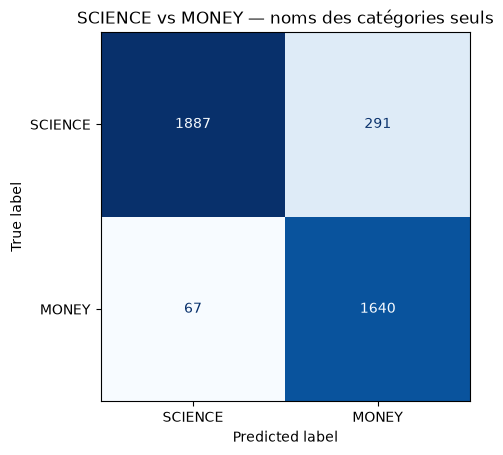

Classification:   0%|          | 0/31 [00:00<?, ?it/s]

Classification:   3%|▎         | 1/31 [00:01<00:30,  1.00s/it]

Classification:   6%|▋         | 2/31 [00:01<00:26,  1.09it/s]

Classification:  10%|▉         | 3/31 [00:02<00:26,  1.06it/s]

Classification:  13%|█▎        | 4/31 [00:03<00:24,  1.09it/s]

Classification:  16%|█▌        | 5/31 [00:04<00:24,  1.07it/s]

... (24 outputs left out)

Classification:  97%|█████████▋| 30/31 [00:36<00:01,  1.42s/it]

Classification: 100%|██████████| 31/31 [00:37<00:00,  1.14s/it]

Classification: 100%|██████████| 31/31 [00:37<00:00,  1.20s/it]


=== SCIENCE vs MONEY — avec dictionnaire de mots-clés ===
              precision    recall  f1-score   support

     SCIENCE      0.952     0.942     0.947      2178
       MONEY      0.927     0.939     0.933      1707

    accuracy                          0.941      3885
   macro avg      0.939     0.941     0.940      3885
weighted avg      0.941     0.941     0.941      3885



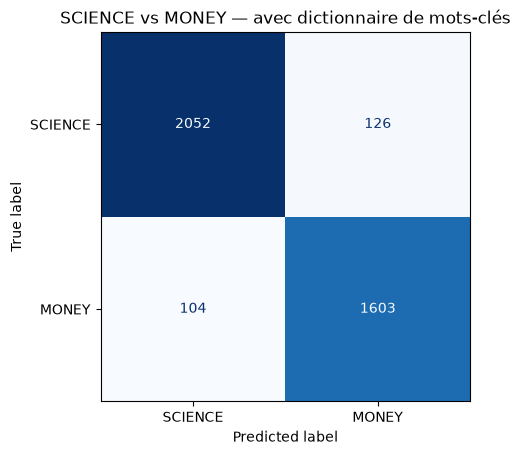

In [16]:
selected_categories = ['SCIENCE', 'MONEY']
texts, categories = select_texts_categories(corpus, selected_categories)

_ = evaluate(model, texts, categories, selected_categories,
             title='SCIENCE vs MONEY — noms des catégories seuls')
_ = evaluate(model, texts, categories, selected_categories, category_descriptors,
             title='SCIENCE vs MONEY — avec dictionnaire de mots-clés')

**b.** Veuillez réaliser une expérience de classification non supervisée sur les articles des catégories `['TECH', 'ARTS', 'COLLEGE']`.

TECH       : 2082 articles
ARTS       : 1509 articles
COLLEGE    : 1144 articles


Classification:   0%|          | 0/37 [00:00<?, ?it/s]

Classification:   3%|▎         | 1/37 [00:01<00:36,  1.03s/it]

Classification:   5%|▌         | 2/37 [00:02<00:36,  1.03s/it]

Classification:   8%|▊         | 3/37 [00:03<00:35,  1.05s/it]

Classification:  11%|█         | 4/37 [00:04<00:34,  1.03s/it]

... (31 outputs left out)

Classification:  97%|█████████▋| 36/37 [00:48<00:01,  1.31s/it]

Classification: 100%|██████████| 37/37 [00:49<00:00,  1.28s/it]

Classification: 100%|██████████| 37/37 [00:49<00:00,  1.33s/it]


=== TECH vs ARTS vs COLLEGE — noms des catégories seuls ===
              precision    recall  f1-score   support

        TECH      0.918     0.762     0.833      2082
        ARTS      0.754     0.900     0.820      1509
     COLLEGE      0.821     0.865     0.842      1144

    accuracy                          0.831      4735
   macro avg      0.831     0.842     0.832      4735
weighted avg      0.842     0.831     0.831      4735



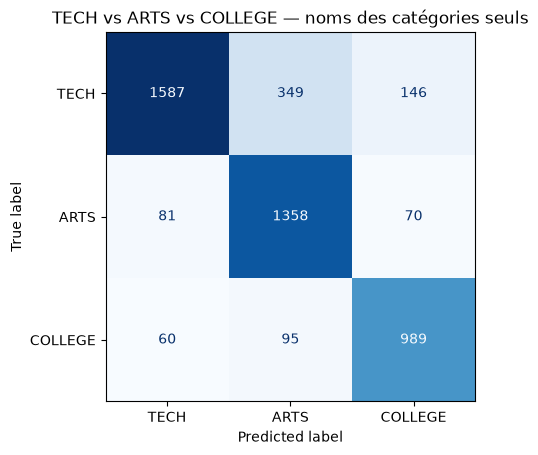

Classification:   0%|          | 0/37 [00:00<?, ?it/s]

Classification:   3%|▎         | 1/37 [00:01<00:36,  1.03s/it]

Classification:   5%|▌         | 2/37 [00:02<00:35,  1.02s/it]

Classification:   8%|▊         | 3/37 [00:03<00:35,  1.05s/it]

Classification:  11%|█         | 4/37 [00:04<00:34,  1.04s/it]

Classification:  14%|█▎        | 5/37 [00:05<00:35,  1.12s/it]

... (30 outputs left out)

Classification:  97%|█████████▋| 36/37 [00:46<00:01,  1.28s/it]

Classification: 100%|██████████| 37/37 [00:47<00:00,  1.26s/it]

Classification: 100%|██████████| 37/37 [00:47<00:00,  1.28s/it]


=== TECH vs ARTS vs COLLEGE — avec dictionnaire de mots-clés ===
              precision    recall  f1-score   support

        TECH      0.912     0.906     0.909      2082
        ARTS      0.872     0.901     0.886      1509
     COLLEGE      0.876     0.848     0.862      1144

    accuracy                          0.891      4735
   macro avg      0.887     0.885     0.886      4735
weighted avg      0.891     0.891     0.891      4735



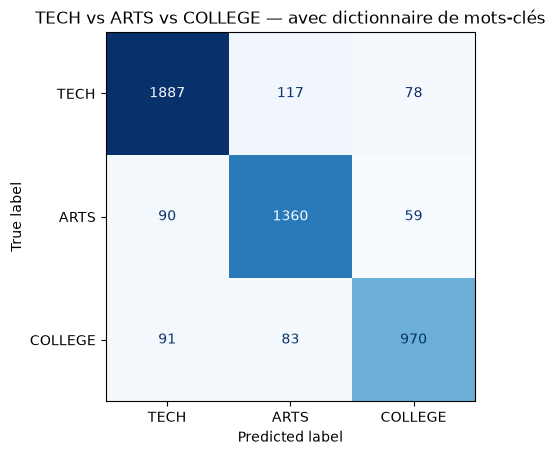

In [17]:
selected_categories = ['TECH', 'ARTS', 'COLLEGE']
texts, categories = select_texts_categories(corpus, selected_categories)

_ = evaluate(model, texts, categories, selected_categories,
             title='TECH vs ARTS vs COLLEGE — noms des catégories seuls')
_ = evaluate(model, texts, categories, selected_categories, category_descriptors,
             title='TECH vs ARTS vs COLLEGE — avec dictionnaire de mots-clés')

**c.** Veuillez discuter chaque expérience en termes de scores.  Pour chacune, veuillez comparer les scores avec ou sans le dictionnaire qui explicite les catégories, et indiquer 1-2 observations expérimentales sur la meilleure forme de définition des catégories.  Au final, veuillez donner votre opinion sur la qualité de la classification non supervisée et l'utilité du dictionnaire.

### Discussion

**Expérience 3.a — SCIENCE vs MONEY (3885 articles)**

| Définition des catégories | Accuracy | F1 macro | Rappel SCIENCE | Rappel MONEY |
|---|---|---|---|---|
| Noms seuls (`science`, `money`) | 0.908 | 0.907 | 0.866 | 0.961 |
| Dictionnaire de mots-clés | **0.941** | **0.940** | 0.942 | 0.939 |

Avec les noms seuls, le score est déjà élevé (91 %) car les deux thèmes sont sémantiquement très éloignés. Le classifieur est toutefois déséquilibré : il attribue trop d'articles à MONEY (précision MONEY 0.85, rappel SCIENCE 0.87). Le seul mot « money » est un attracteur assez large, tandis que « science » ne couvre pas bien les articles sur l'espace, les animaux ou la nature. Le dictionnaire corrige ce biais : les rappels deviennent équilibrés (~0.94) et l'accuracy gagne 3.3 points.

**Expérience 3.b — TECH vs ARTS vs COLLEGE (4735 articles)**

| Définition des catégories | Accuracy | F1 macro | Rappel TECH | Rappel ARTS | Rappel COLLEGE |
|---|---|---|---|---|---|
| Noms seuls (`tech`, `arts`, `college`) | 0.831 | 0.832 | 0.762 | 0.900 | 0.865 |
| Dictionnaire de mots-clés | **0.891** | **0.886** | 0.906 | 0.901 | 0.848 |

Le problème à trois classes est plus difficile (chance = 33 % au lieu de 50 %), et les scores sont plus bas. Sans dictionnaire, beaucoup d'articles TECH sont mal classés (rappel 0.76), surtout vers ARTS (précision ARTS 0.75) : « tech » est une abréviation peu informative pour le modèle, et les articles sur les jeux vidéo, le design ou les réseaux sociaux ressemblent à des sujets culturels. Les mots-clés (*internet, smartphone, apple, google, facebook, software…*) font remonter le rappel TECH à 0.91 et l'accuracy gagne 6 points. COLLEGE reste la classe la plus difficile : beaucoup d'articles parlent d'étudiants dans des contextes variés (politique, faits divers, culture), ce qui crée de la confusion avec les deux autres classes.

**Observations expérimentales sur la meilleure forme de définition des catégories** (essais réalisés en variant le dictionnaire) :
1. **Le nombre et la concrétude des mots-clés comptent.** La définition initiale à 2 mots (`'science, biology'`, `'money, funds'`) était *pire* que le nom seul (0.863 contre 0.908 pour SCIENCE/MONEY) : un mot trop spécifique (*biology*) ou rare dans le corpus (*funds*) tire l'embedding dans une mauvaise direction. Avec 5 mots on obtient 0.928 / 0.854, et avec 8-10 mots 0.941 / 0.891. Il faut des mots **fréquents dans les articles réels** de la catégorie (p.ex. *credit card, retirement, mortgage* pour MONEY, des marques comme *apple, google, facebook* pour TECH) plutôt que des synonymes abstraits du nom.
2. **Une liste de mots-clés fonctionne au moins aussi bien qu'une définition en phrase.** Une définition du type *« News about scientific research and discoveries in biology, physics and space. »* donne 0.921 (SCIENCE/MONEY) et 0.886 (TECH/ARTS/COLLEGE), un peu en dessous des listes de mots-clés. Le style de la description influence l'embedding : une liste couvre mieux la diversité des sous-thèmes d'une rubrique.

**Opinion générale.** La classification non supervisée par similarité d'embeddings Sentence BERT est étonnamment efficace : sans aucun exemple étiqueté ni entraînement, on atteint 94 % sur 2 classes et 89 % sur 3 classes, avec un petit modèle (all-MiniLM-L6-v2, 384 dimensions). Elle a cependant des limites : la qualité dépend fortement de la manière de décrire les catégories, les catégories proches ou floues (COLLEGE vs ARTS, TECH vs SCIENCE) restent confondues, et les catégories d'un journal sont des choix éditoriaux qui ne correspondent pas toujours au contenu sémantique. Un classifieur supervisé entraîné sur les mêmes embeddings ferait probablement mieux, mais il demande des données annotées.

Le **dictionnaire est donc très utile** : il améliore l'accuracy de 3 à 6 points et, surtout, il rééquilibre les rappels entre classes. C'est l'unique moyen d'injecter de la connaissance du domaine dans une méthode zero-shot, à condition d'être construit avec soin (mots variés, concrets, représentatifs du vocabulaire des articles), et idéalement validé sur un petit échantillon étiqueté.

**Fin du Labo.**  Veuillez nettoyer ce notebook en gardant seulement les résultats et les commentaires demandés, l'enregistrer, et le soumettre comme devoir sur Cyberlearn.